In [1]:
import pandas as pd

In [2]:
file_path = 'cleaned_data.csv'
data = pd.read_csv(file_path)

In [3]:
# Save it with a new name
new_file_path = 'cleaned_data for EDA.csv'
data.to_csv(new_file_path, index=False)

print(f"File renamed and saved as: {new_file_path}")

File renamed and saved as: cleaned_data for EDA.csv


In [4]:
print("Column Names in the Dataset:")
print(data.columns)

Column Names in the Dataset:
Index(['date', 'total energy consumption', 'biomass', 'hydropower', 'solar',
       'other renewables', 'nuclear', 'natural gas', 'pumped storage',
       'other conventional', 'coal', 'wind', 'prices', 'gdp', 'population',
       'Mean_Temperature', 'HDD', 'CDD', 'Precipitation', 'Wind_Speed',
       'Solar_Radiation_MJ_m2', 'aviation_co2', 'electricity_co2',
       'industry_co2', 'residential_co2', 'transport_co2',
       'total CO2 emissions', 'primary energy consumption', 'GDP per capita',
       'CO2 emissions per capita', 'PEC per capita', 'COVID-19',
       'Russia-Ukraine War'],
      dtype='object')


In [2]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [3]:
file_path = 'cleaned_data for EDA.csv'
data = pd.read_csv(file_path)

In [4]:
# Convert 'date' column to datetime, auto-detecting the format
data['date'] = pd.to_datetime(data['date'], errors='coerce')

In [5]:
# Group by month and calculate the mean, keeping the date as the index
monthly_data = data.groupby(pd.Grouper(key='date', freq='M')).mean().reset_index()

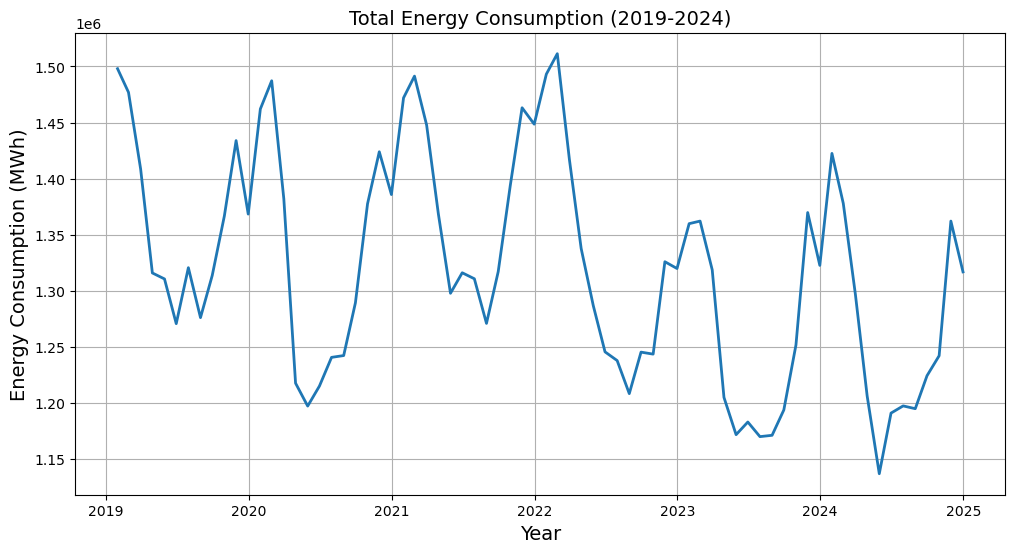

In [7]:
# Plot total energy consumption
plt.figure(figsize=(12, 6))
plt.plot(monthly_data['date'], monthly_data['total energy consumption'], label='Total Energy Consumption', linewidth=2)
plt.title('Total Energy Consumption (2019-2024)', fontsize=14)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Energy Consumption (MWh)', fontsize=14)
#plt.legend()
plt.grid()
#plt.tight_layout()
plt.savefig("plots/01_energy_trend.png") 
plt.show()

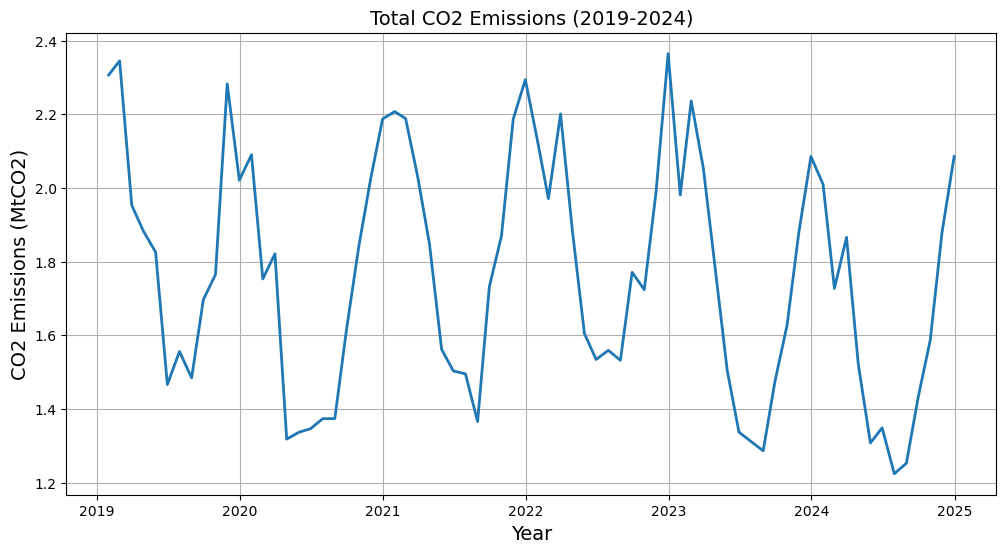

In [8]:
# Plot total CO2 emissions
plt.figure(figsize=(12, 6))
plt.plot(monthly_data['date'], monthly_data['total CO2 emissions'], label='Total CO2 Emissions', linewidth=2)
plt.title('Total CO2 Emissions (2019-2024)', fontsize=14)
plt.xlabel('Year', fontsize=14)
plt.ylabel('CO2 Emissions (MtCO2)', fontsize=14)
#plt.legend()
plt.grid()
#plt.tight_layout()
plt.savefig("plots/02_co2_trend.png")
plt.show()

In [9]:
# Visualize Energy Generation by Source 
generation_sources = ['coal', 'wind', 'solar', 'natural gas', 'nuclear', 'hydropower', 'biomass']

In [10]:
# Define unique colors for each source
colors = ['black', 'green', 'orange', 'purple', 'red', 'blue', 'magenta']

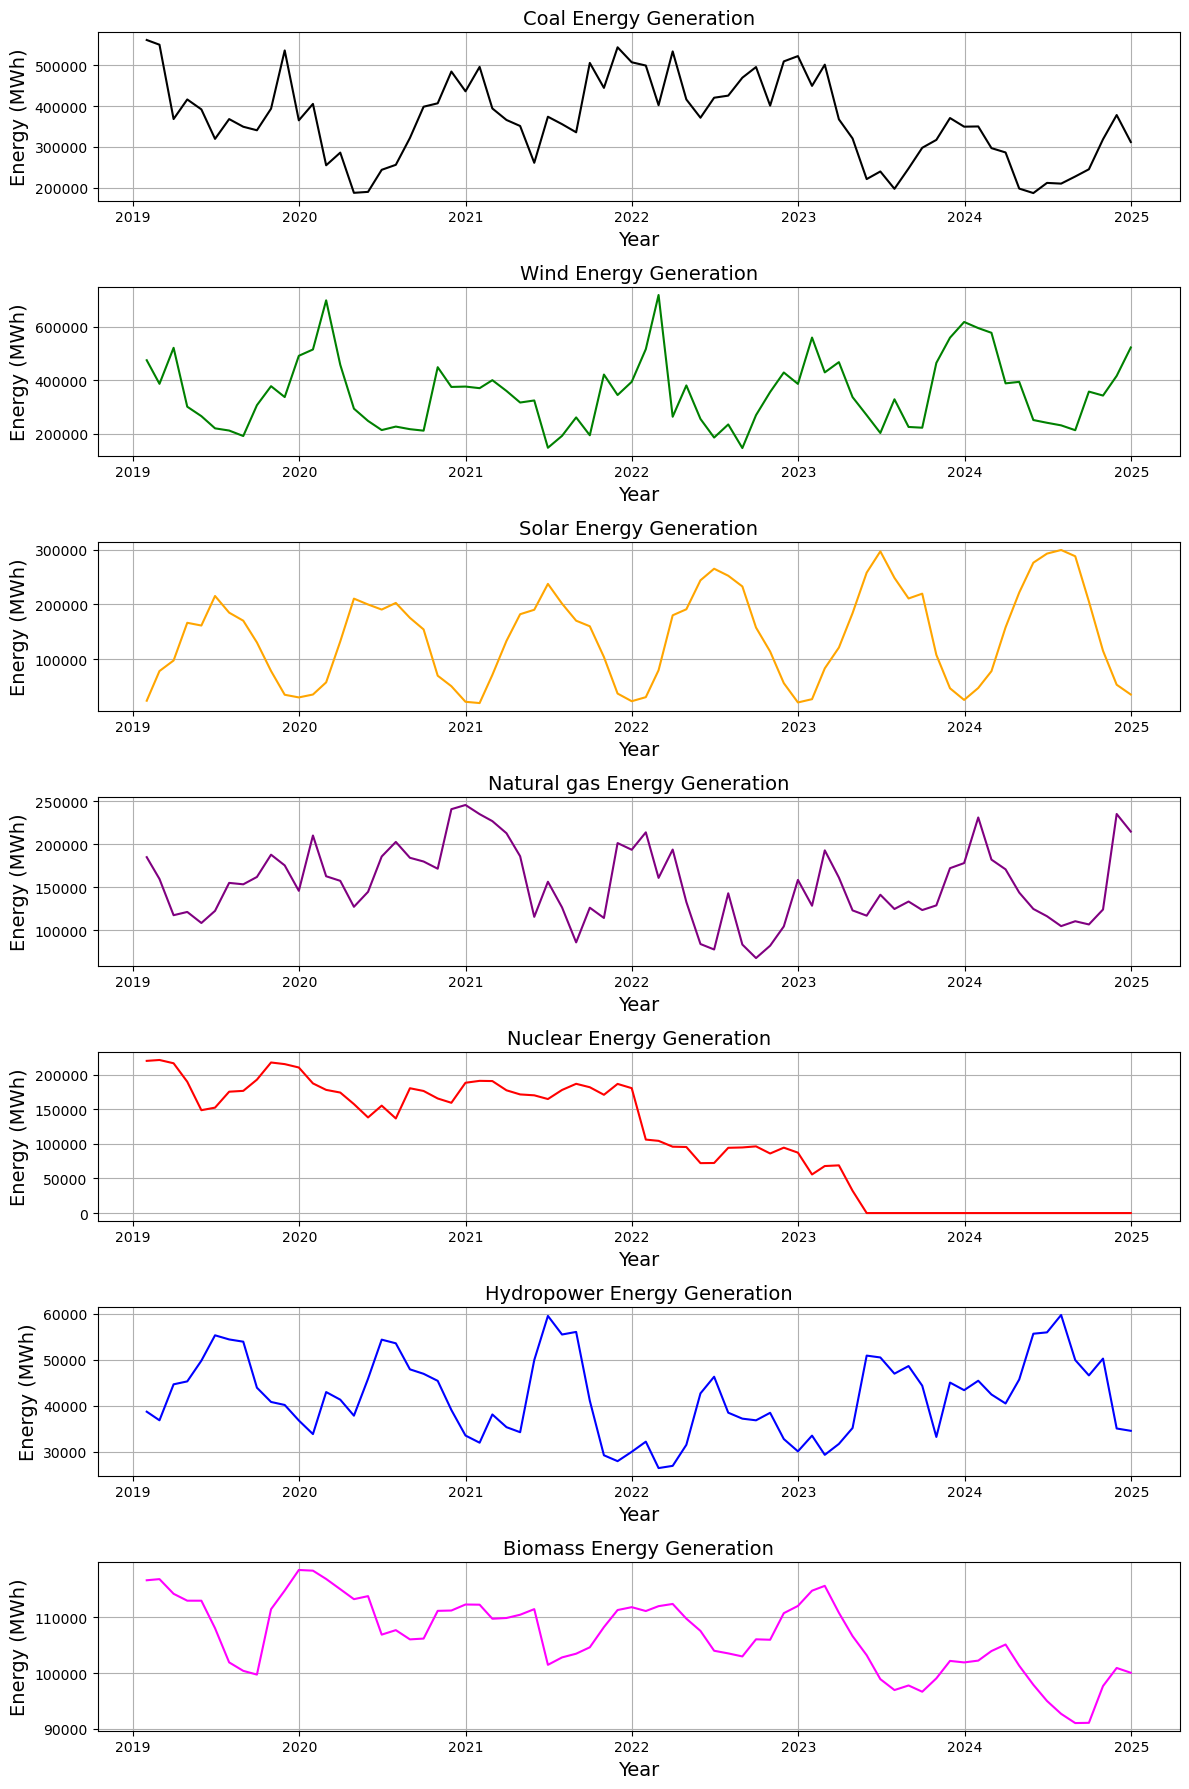

In [11]:
# Create subplots
fig, axes = plt.subplots(nrows=len(generation_sources), ncols=1, figsize=(12, 18), sharex=False)

# Plot each source in its own subplot
for i, (source, color) in enumerate(zip(generation_sources, colors)):
    axes[i].plot(monthly_data['date'], monthly_data[source], label=source.capitalize(), color=color, linewidth=1.5)
    axes[i].set_title(f'{source.capitalize()} Energy Generation', fontsize=14)
    axes[i].set_ylabel('Energy (MWh)', fontsize=14)
    axes[i].grid(True)
    #axes[i].legend()

    # Set common x-label
    axes[i].set_xlabel('Year', fontsize=14)

# Adjust layout to prevent overlap
plt.tight_layout()

plt.savefig("plots/03_energy_gen.png")

plt.show()

In [12]:
# Visualize CO2 Emissions by Sector 
emission_sectors = ['aviation_co2', 'electricity_co2', 'industry_co2', 'residential_co2', 'transport_co2']

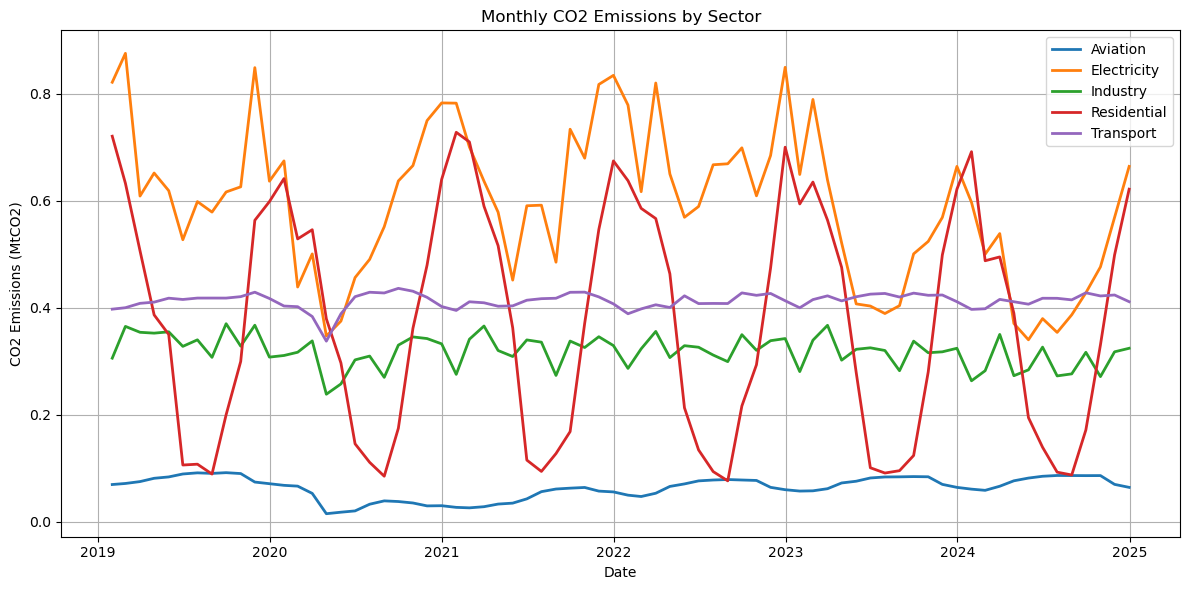

In [13]:
# Plot CO2 emissions by sector
plt.figure(figsize=(12, 6))
for sector in emission_sectors:
    plt.plot(monthly_data['date'], monthly_data[sector], label=sector.replace('_co2', '').capitalize(), linewidth=2)
plt.title('Monthly CO2 Emissions by Sector')
plt.xlabel('Date')
plt.ylabel('CO2 Emissions (MtCO2)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

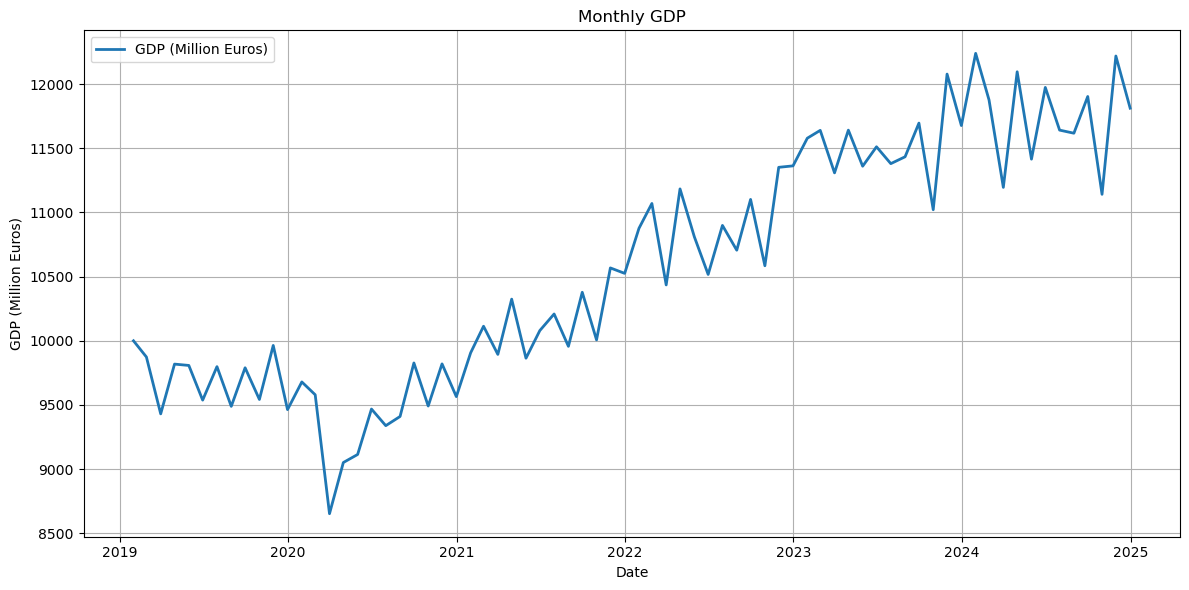

In [15]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_data['date'], monthly_data['gdp'], label='GDP (Million Euros)', linewidth=2)
plt.title('Monthly GDP')
plt.xlabel('Date')
plt.ylabel('GDP (Million Euros)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### Correlation Analysis

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
# Weather features to analyze
weather_features = ['Mean_Temperature', 'HDD', 'CDD', 'Precipitation', 'Wind_Speed', 'Solar_Radiation_MJ_m2']

In [18]:
# Correlation of total energy consumption with weather features
correlation_weather = data[['total energy consumption'] + weather_features].corr()

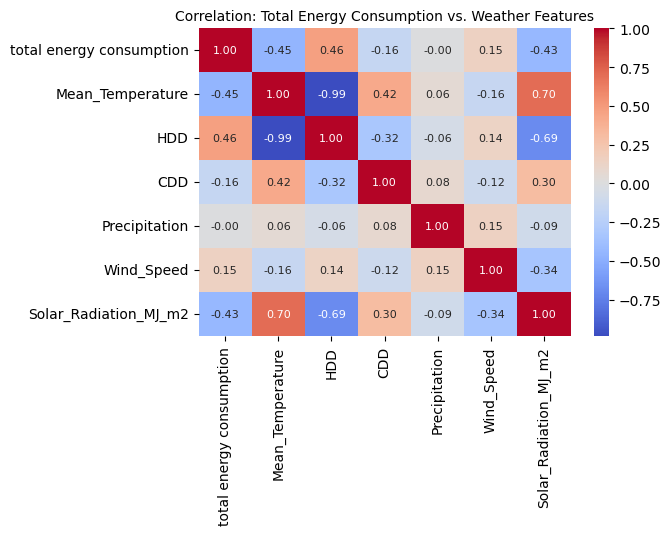

In [19]:
# Visualize the correlation using a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_weather, annot=True, cmap='coolwarm', fmt='.2f', annot_kws={"size": 8})
plt.title('Correlation: Total Energy Consumption vs. Weather Features', fontsize=10)
plt.show()

### Energy Generation vs. Weather

In [20]:
# Energy generation sources and weather features
generation_weather = {
    'wind': 'Wind_Speed',
    'solar': 'Solar_Radiation_MJ_m2',
}

In [21]:
# Scatter plots for energy generation vs. weather
units = {
    'wind': 'Wind Energy Generation (MWh)',
    'solar': 'Solar energy Generation (MWh)',
}

In [22]:
# Correlation analysis
generation_weather_corr = {source: data[source].corr(data[weather]) 
                           for source, weather in generation_weather.items()}

In [23]:
# Display correlations
print("Correlation: Energy Generation vs. Weather Features")
for source, corr in generation_weather_corr.items():
    print(f"{source.capitalize()} vs. {generation_weather[source]}: {corr:.2f}")

Correlation: Energy Generation vs. Weather Features
Wind vs. Wind_Speed: 0.86
Solar vs. Solar_Radiation_MJ_m2: 0.94


In [31]:
# Define custom x-axis labels for different weather variables
custom_x_labels = {
    "Wind_Speed": "Wind Speed (m/s)",  
    "Solar_Radiation_MJ_m2": "Solar Radiation (MJ/m²)",  
    "Mean_Temperature": "Mean Temperature (°C)",  
    #"Precipitation": "Precipitation (mm)"  
}

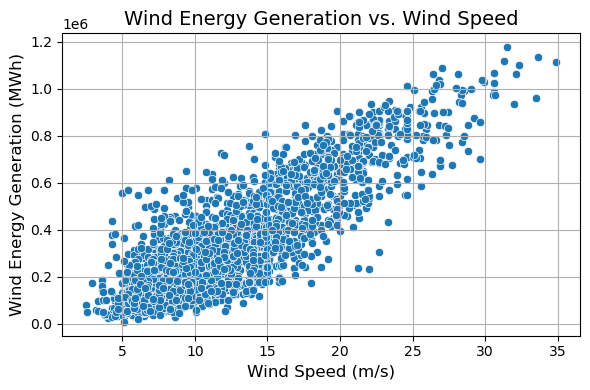

In [32]:
# Define each scatter plot separately
plt.figure(figsize=(6, 4))
sns.scatterplot(data=data, x="Wind_Speed", y="wind")
plt.title("Wind Energy Generation vs. Wind Speed", fontsize=14)
plt.xlabel(custom_x_labels["Wind_Speed"], fontsize=12)
plt.ylabel("Wind Energy Generation (MWh)", fontsize=12)
plt.grid(True)
plt.tight_layout()
#plt.subplots_adjust(left=0.15)
plt.savefig("plots/wind energy_vs_wind speed.png")  
plt.show()

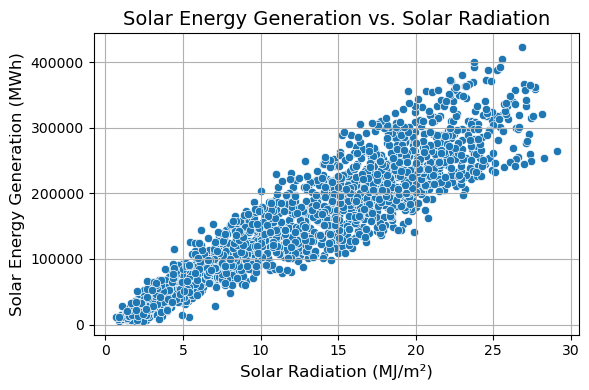

In [33]:
# Solar Radiation vs Solar Energy Generation
plt.figure(figsize=(6, 4))
sns.scatterplot(data=data, x="Solar_Radiation_MJ_m2", y="solar")
plt.title("Solar Energy Generation vs. Solar Radiation", fontsize=14)
plt.xlabel(custom_x_labels["Solar_Radiation_MJ_m2"], fontsize=12)
plt.ylabel("Solar Energy Generation (MWh)", fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/Solar_Energy_vs_Solar_Radiation.png")
plt.show()

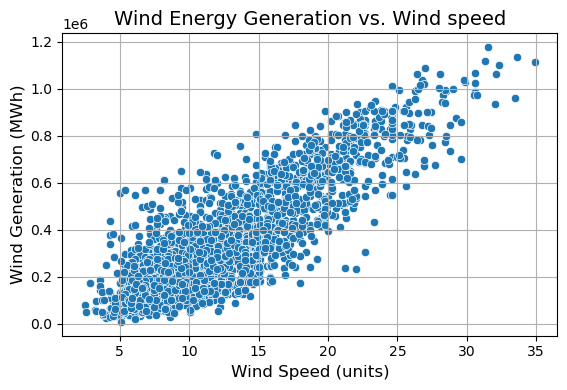

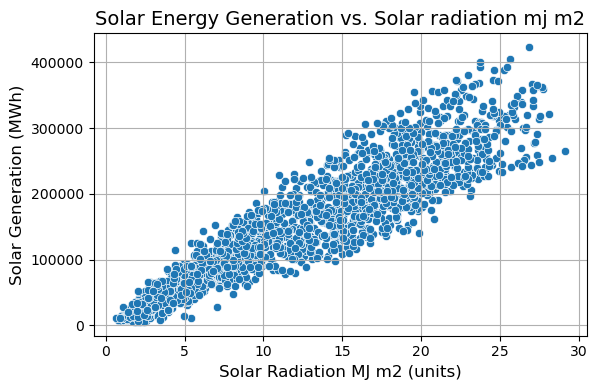

<Figure size 640x480 with 0 Axes>

In [28]:
# Scatter plots for visualization
for source, weather in generation_weather.items():
    plt.figure(figsize=(6, 4))  # Set figure size

    # Create scatter plot
    sns.scatterplot(data=data, x=weather, y=source)

    # Modify plot labels and title
    plt.title(f"{source.capitalize()} Energy Generation vs. {weather.replace('_', ' ').capitalize()}", fontsize=14)  

    # Assign different x-axis labels dynamically
    x_label = custom_x_labels.get(weather, weather.replace('_', ' ') + " (units)")  # Default if not in dict
    plt.xlabel(x_label, fontsize=12)  # Set specific x-axis label

    plt.ylabel(f"{source.capitalize()} Generation (MWh)", fontsize=12)  

    plt.grid(True)  # Add grid
    plt.tight_layout()  # Adjust layout
    plt.subplots_adjust(left=0.15)  # Prevent y-label from getting cut

    

    plt.show()  # Display the plot
    
# Save figure before showing
plt.savefig(f"plots/{source}_vs_{weather}.png")  

### Energy Prices Over Time

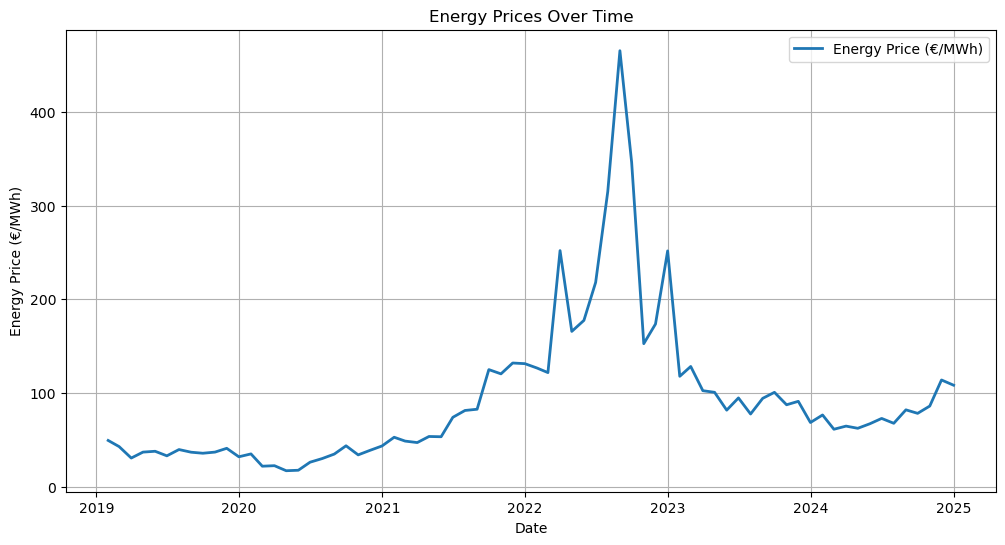

In [190]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_data['date'], monthly_data['prices'], label='Energy Price (€/MWh)', linewidth=2)
plt.xlabel('Date')
plt.ylabel('Energy Price (€/MWh)')
plt.title('Energy Prices Over Time')
plt.legend()
plt.grid()
plt.show()

### CO2 Emissions vs. Energy Consumption ###

Examine how sector-wise CO2 emissions (aviation_co2, transport_co2, etc.) are related to:
1. Total energy consumption.
2. Energy generation by source.

In [192]:
# CO2 emission features
co2_features = ['aviation_co2', 'transport_co2', 'residential_co2', 
                'industry_co2', 'electricity_co2', 'total CO2 emissions']

In [193]:
# Correlation of CO2 emissions with total energy consumption and generation sources
corr_co2 = data[['total energy consumption', 'coal', 'wind', 'solar', 
                 'natural gas', 'nuclear'] + co2_features].corr()

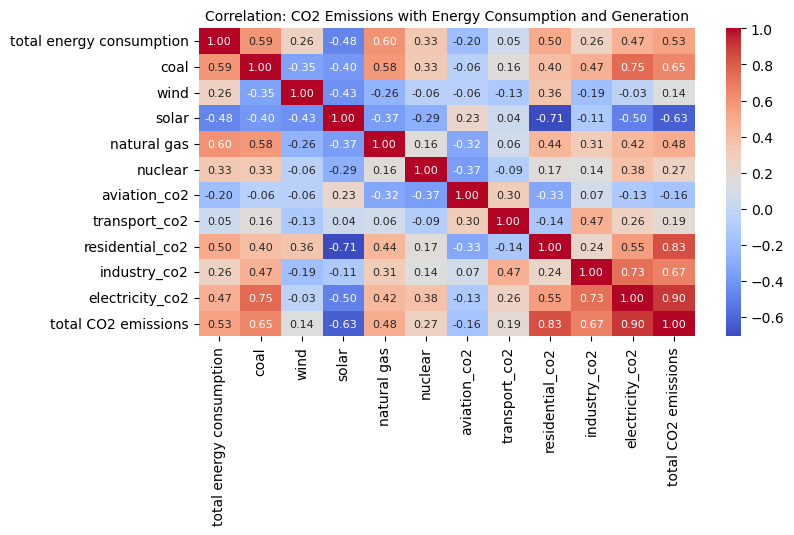

In [194]:
# Visualize using a heatmap
plt.figure(figsize=(8, 4))
sns.heatmap(corr_co2, annot=True, cmap='coolwarm', fmt='.2f', annot_kws={"size": 8})
plt.title('Correlation: CO2 Emissions with Energy Consumption and Generation', fontsize=10)
plt.show()

### Event Analysis

Understand the impact of major events (COVID-19 and Russia-Ukraine war) on energy consumption, generation, emissions, and economic indicators.

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

In [7]:
# Define event periods
covid_wave1_start, covid_wave1_end = pd.to_datetime('2020-02-01'), pd.to_datetime('2020-05-31')
covid_wave2_start, covid_wave2_end = pd.to_datetime('2020-10-01'), pd.to_datetime('2021-02-28')
war_start = pd.to_datetime('2022-02-24')

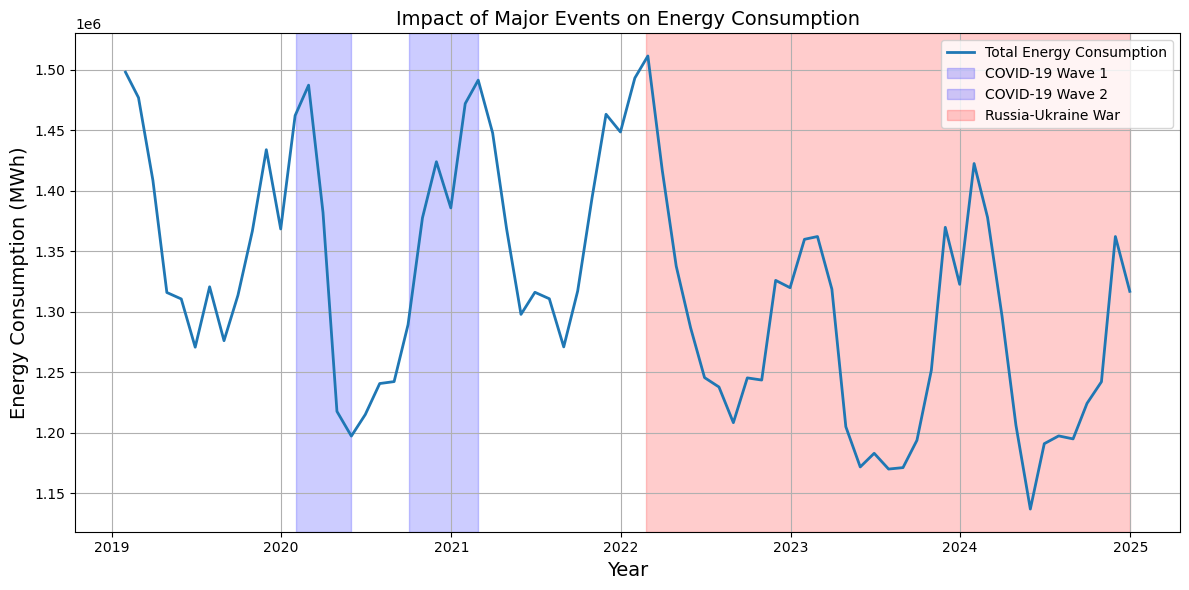

In [10]:
# Plot total energy consumption with event shading
plt.figure(figsize=(12, 6))
plt.plot(monthly_data['date'], monthly_data['total energy consumption'], label='Total Energy Consumption', linewidth=2)

# Add shaded regions for events
plt.axvspan(covid_wave1_start, covid_wave1_end, color='blue', alpha=0.2, label='COVID-19 Wave 1')
plt.axvspan(covid_wave2_start, covid_wave2_end, color='blue', alpha=0.2, label='COVID-19 Wave 2')
plt.axvspan(war_start, monthly_data['date'].max(), color='red', alpha=0.2, label='Russia-Ukraine War')

# Formatting the plot
plt.title('Impact of Major Events on Energy Consumption', fontsize=14)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Energy Consumption (MWh)', fontsize=14)
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/Events vs Energy Consumption.png")
plt.show()

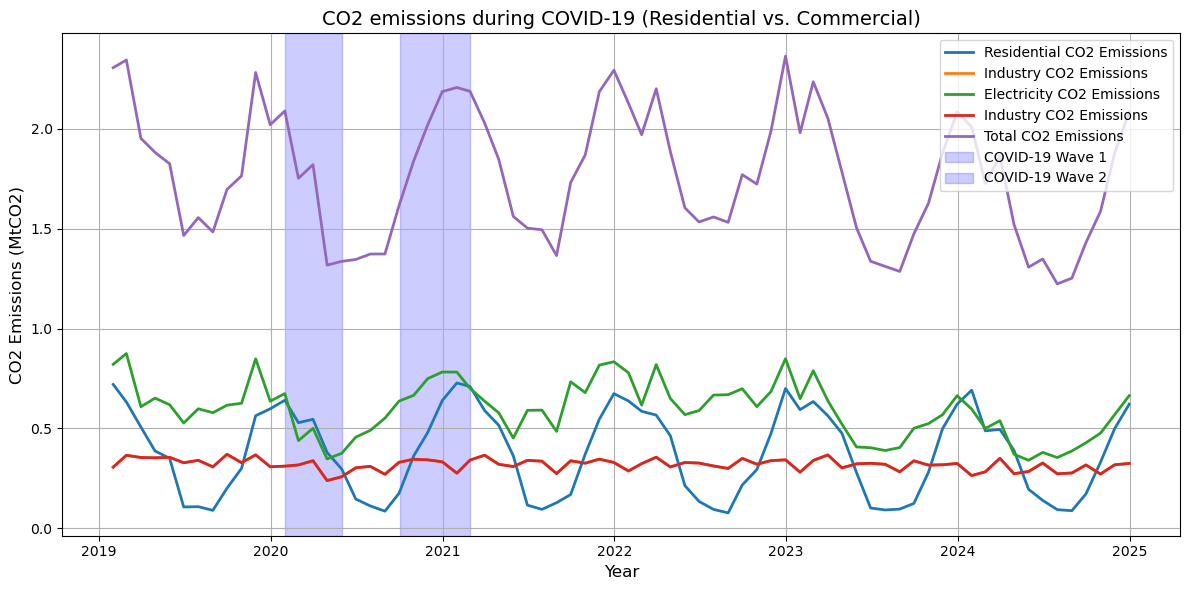

In [42]:
# Residential vs. Commercial CO2 Emissions During COVID-19
plt.figure(figsize=(12, 6))
plt.plot(monthly_data['date'], monthly_data['residential_co2'], label='Residential CO2 Emissions', linewidth=2)
plt.plot(monthly_data['date'], monthly_data['industry_co2'], label='Industry CO2 Emissions', linewidth=2)
plt.plot(monthly_data['date'], monthly_data['electricity_co2'], label='Electricity CO2 Emissions', linewidth=2)
plt.plot(monthly_data['date'], monthly_data['industry_co2'], label='Industry CO2 Emissions', linewidth=2)
plt.plot(monthly_data['date'], monthly_data['total CO2 emissions'], label='Total CO2 Emissions', linewidth=2)
plt.axvspan(covid_wave1_start, covid_wave1_end, color='blue', alpha=0.2, label='COVID-19 Wave 1')
plt.axvspan(covid_wave2_start, covid_wave2_end, color='blue', alpha=0.2, label='COVID-19 Wave 2')
plt.title('CO2 emissions during COVID-19 (Residential vs. Commercial)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('CO2 Emissions (MtCO2)', fontsize=12)
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/Residential vs. Commercial CO2 Emissions during COVID-19.png")
plt.show()

Percentage Change Analysis with Monthly Aggregation

In [208]:
# Define periods for COVID-19 (monthly aggregated data)
pre_covid_wave1 = monthly_data[monthly_data['date'] < covid_wave1_start]
during_covid_wave1 = monthly_data[(monthly_data['date'] >= covid_wave1_start) & (monthly_data['date'] <= covid_wave1_end)]
during_covid_wave2 = monthly_data[(monthly_data['date'] >= covid_wave2_start) & (monthly_data['date'] <= covid_wave2_end)]
post_covid = monthly_data[monthly_data['date'] > covid_wave2_end]

In [209]:
# Define periods for Russia-Ukraine War (monthly aggregated data)
pre_war = monthly_data[monthly_data['date'] < war_start]
during_war = monthly_data[monthly_data['date'] >= war_start]

In [210]:
# Function to calculate mean values for pre-, during-, and post-event periods
def calculate_changes(pre_period, during_period, post_period=None):
    pre_mean = pre_period['total energy consumption'].mean()
    during_mean = during_period['total energy consumption'].mean()
    post_mean = post_period['total energy consumption'].mean() if post_period is not None else None

    changes = {
        'Pre-Event': pre_mean,
        'During Event': during_mean,
    }
    if post_period is not None:
        changes['Post-Event'] = post_mean
    return changes

In [211]:
# Changes for COVID-19 waves
covid_wave1_changes = calculate_changes(pre_covid_wave1, during_covid_wave1)
covid_wave2_changes = calculate_changes(during_covid_wave1, during_covid_wave2, post_covid)

In [212]:
# Changes for Russia-Ukraine War
war_changes = calculate_changes(pre_war, during_war)

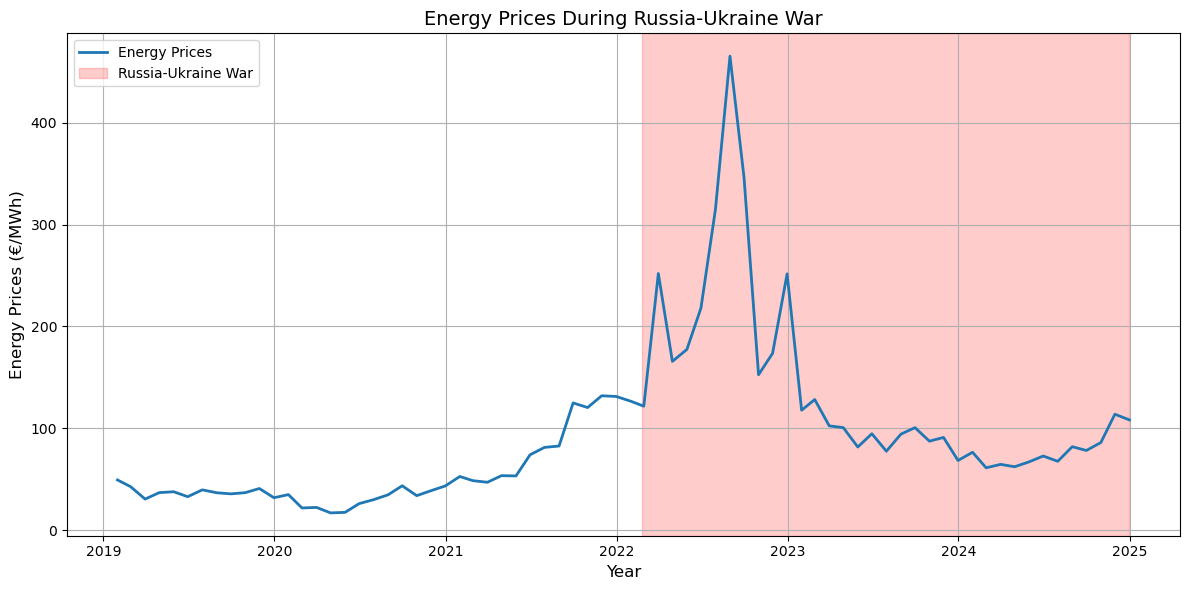

In [43]:
# Energy Prices During Russia-Ukraine War 
plt.figure(figsize=(12, 6))
plt.plot(monthly_data['date'], monthly_data['prices'], label='Energy Prices', linewidth=2)
plt.axvspan(war_start, monthly_data['date'].max(), color='red', alpha=0.2, label='Russia-Ukraine War')
plt.title('Energy Prices During Russia-Ukraine War', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Energy Prices (€/MWh)', fontsize=12)
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/Energy Prices during Russia-Ukraine War.png")
plt.show()

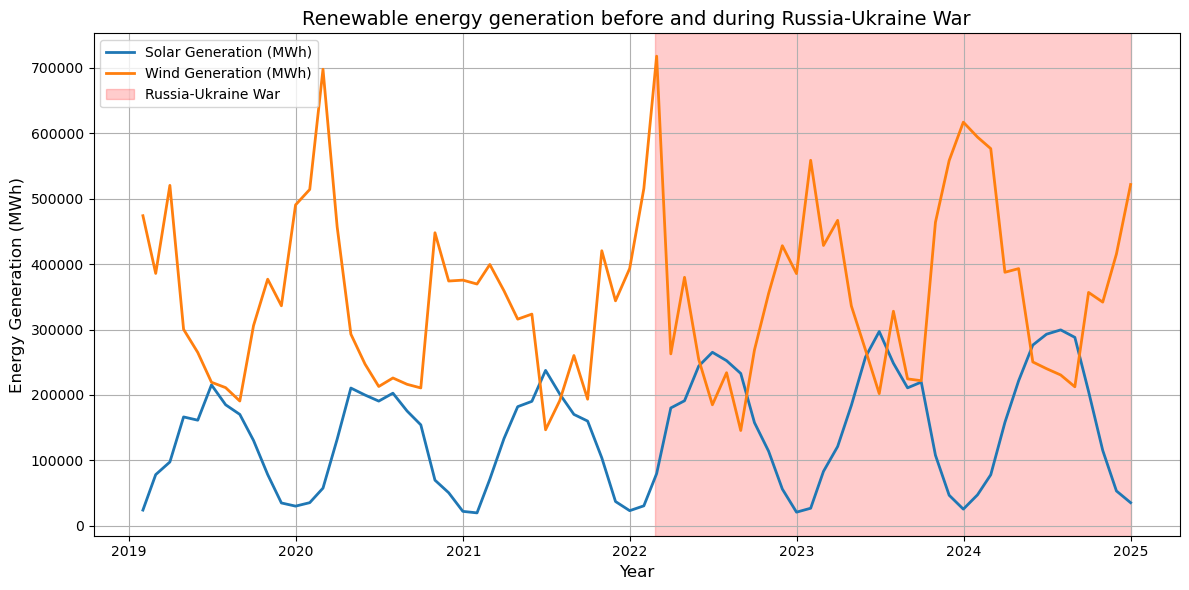

In [8]:
# Solar and Wind Generation Before and During Russia-Ukraine War
plt.figure(figsize=(12, 6))
plt.plot(monthly_data['date'], monthly_data['solar'], label='Solar Generation (MWh)', linewidth=2)
plt.plot(monthly_data['date'], monthly_data['wind'], label='Wind Generation (MWh)', linewidth=2)
plt.axvspan(war_start, monthly_data['date'].max(), color='red', alpha=0.2, label='Russia-Ukraine War')
plt.title('Renewable energy generation before and during Russia-Ukraine War', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Energy Generation (MWh)', fontsize=12)
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("plots/Renewable energy generation before and during war.png")
plt.show()

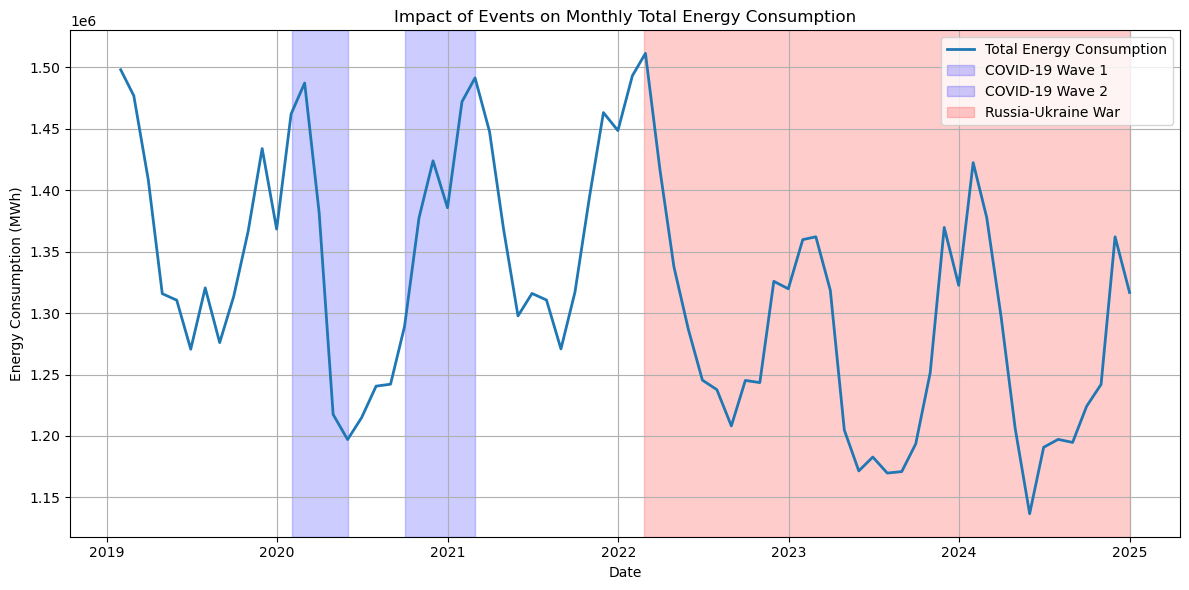

In [215]:
# Impact of Events on Total Energy Consumption 
plt.figure(figsize=(12, 6))
plt.plot(monthly_data['date'], monthly_data['total energy consumption'], label='Total Energy Consumption', linewidth=2)
plt.axvspan(covid_wave1_start, covid_wave1_end, color='blue', alpha=0.2, label='COVID-19 Wave 1')
plt.axvspan(covid_wave2_start, covid_wave2_end, color='blue', alpha=0.2, label='COVID-19 Wave 2')
plt.axvspan(war_start, monthly_data['date'].max(), color='red', alpha=0.2, label='Russia-Ukraine War')
plt.title('Impact of Events on Monthly Total Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MWh)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### Correlation and Multicollinearity Checks (for energy) ###

In [24]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.cluster.hierarchy import linkage, dendrogram

In [25]:
# Define target and auxiliary variables
target_variables = ['total energy consumption']
auxiliary_variables = [
    'biomass', 'hydropower', 'nuclear', 'natural gas', 'pumped storage', 'coal', 
    'industry_co2', 'residential_co2', 'transport_co2', 'CO2 emissions per capita', 
    'prices', 'COVID-19', 'Russia-Ukraine War', 'gdp', 'population',
    'solar', 'wind', 'Solar_Radiation_MJ_m2', 'Mean_Temperature', 
    'primary energy consumption', 'Wind_Speed', 'total CO2 emissions'
]

In [26]:
# Select relevant columns for analysis
analysis_data = data[target_variables + auxiliary_variables]

In [27]:
# Group variables into categories
groups = {
    "Energy Production": ['biomass', 'hydropower', 'nuclear', 'natural gas', 'pumped storage', 'coal', 'solar', 'wind'],
    "CO2 Emissions": ['industry_co2', 'residential_co2', 'transport_co2', 'CO2 emissions per capita', 'total CO2 emissions'],
    "Economic Indicators": ['prices', 'gdp', 'population'],
    "Climate Features": ['Solar_Radiation_MJ_m2', 'Mean_Temperature', 'Wind_Speed'],
    "External Factors": ['COVID-19', 'Russia-Ukraine War']
}

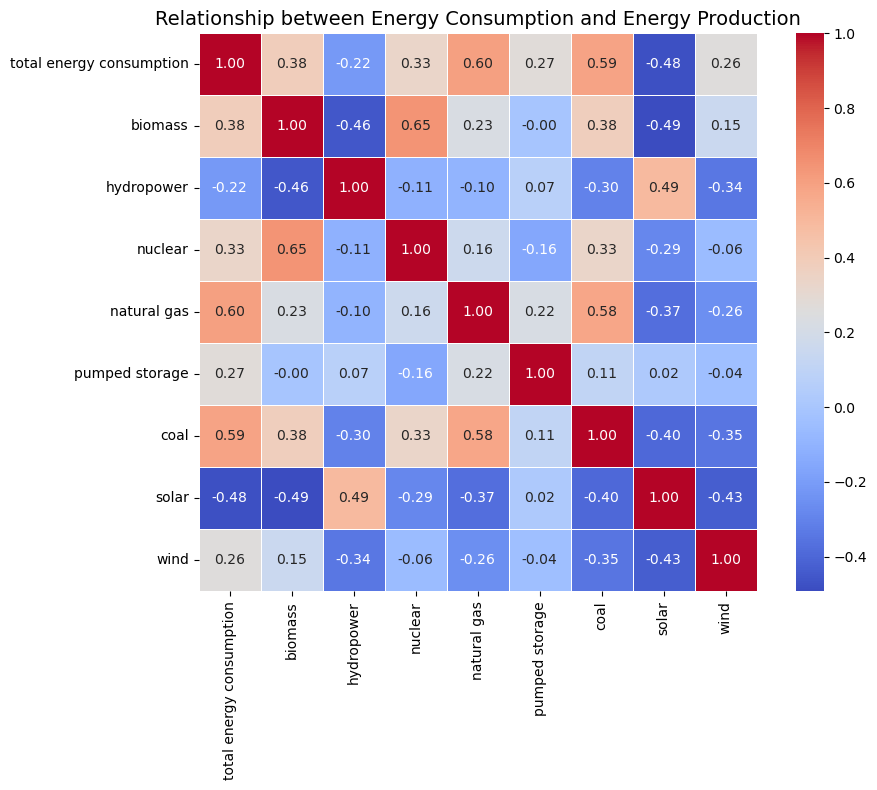

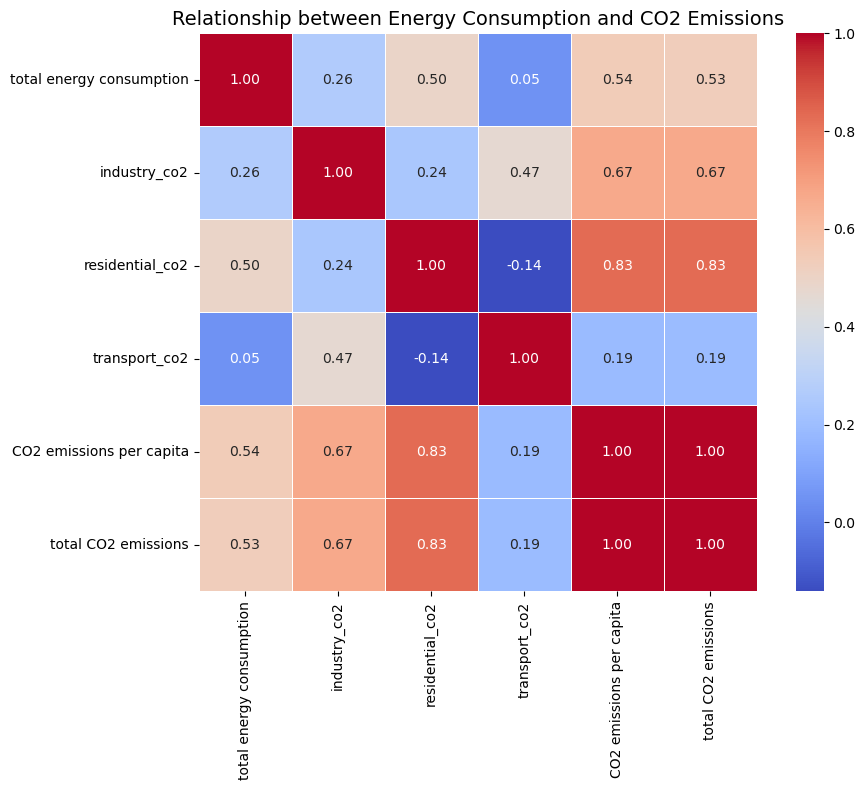

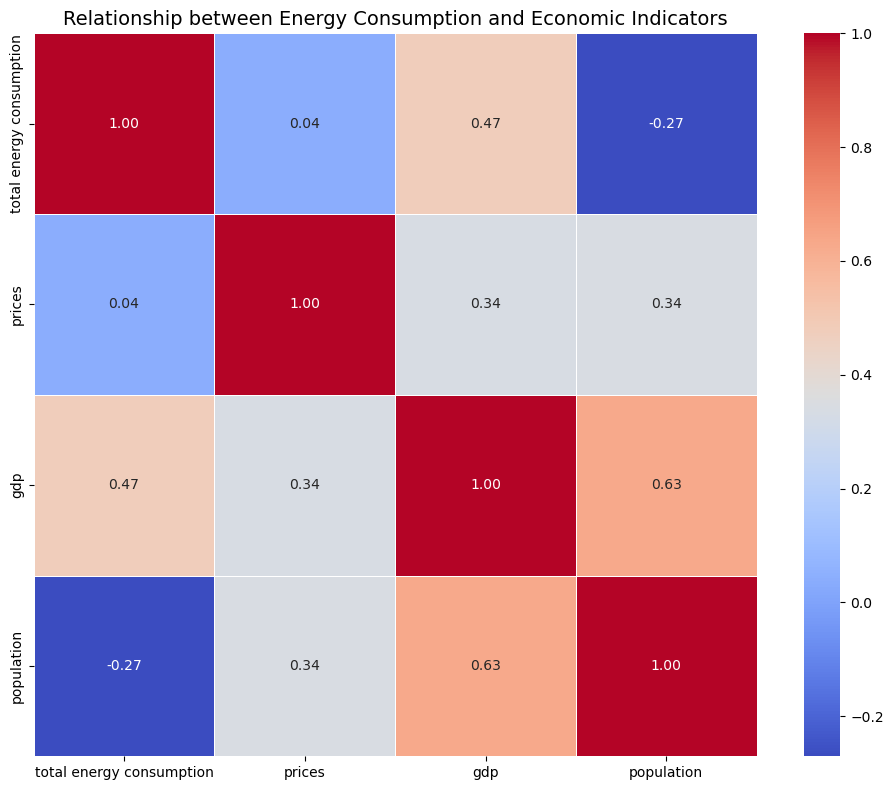

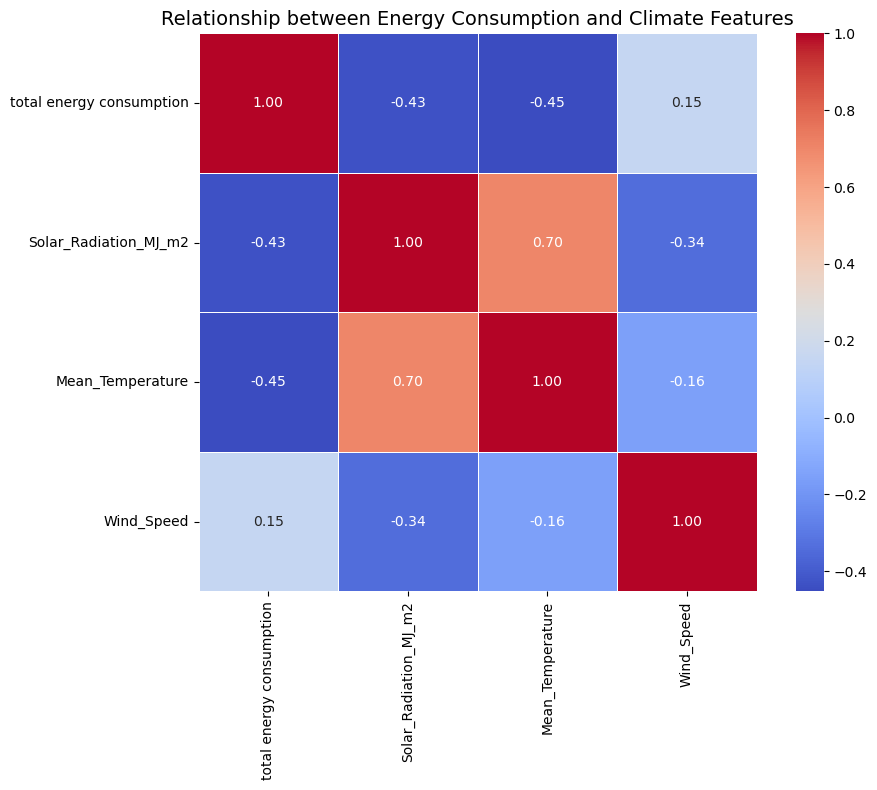

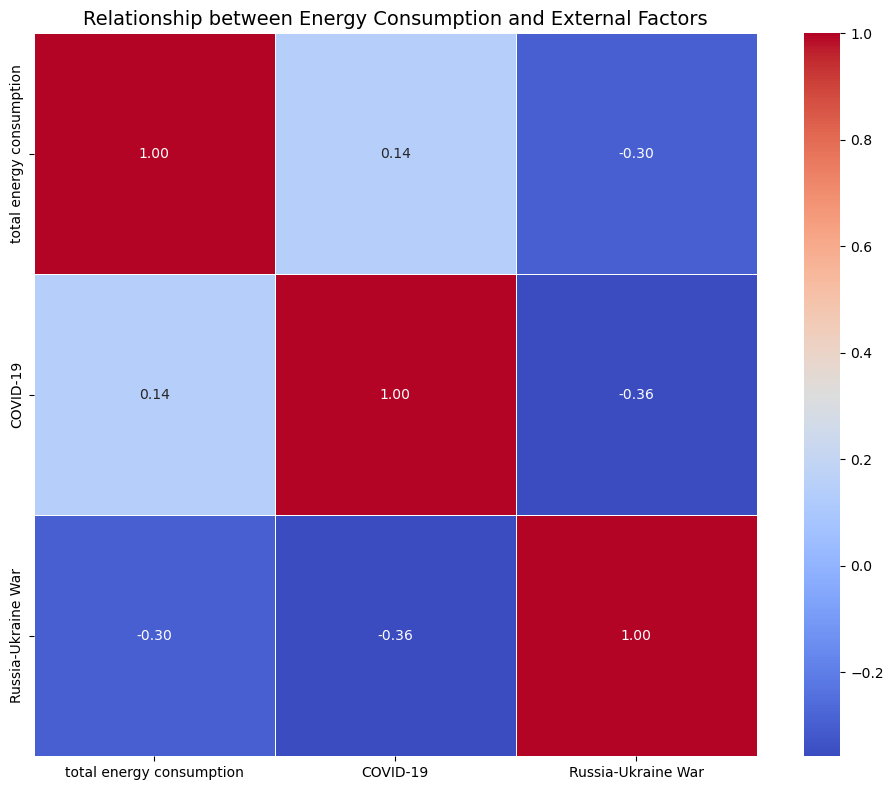

In [28]:
# Perform and plot correlation for each group
for group_name, variables in groups.items():
    # Ensure target variables are included in each group
    group_data = analysis_data[target_variables + variables]
    
    correlation_matrix = group_data.corr()
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f",
        cbar=True, square=True, linewidths=0.5
    )
    plt.title(f"Relationship between Energy Consumption and {group_name}", fontsize=14)
    plt.tight_layout()
    
    # Dynamically generate a filename based on the group name
    filename = f"plots/Correlation_energy_{group_name.replace(' ', '_')}.png"
    
    plt.savefig(filename, bbox_inches='tight')  
    
    plt.show()

#### Multicollinearity Check ####

In [223]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [14]:
# Define target variables
target_energy = 'total_energy_consumption'  # Target for Energy Model

In [15]:
energy_features = ['biomass', 'hydropower', 'nuclear', 'natural gas', 'coal', 
                   'solar', 'wind', 'prices', 'gdp', 'population', 'GDP per capita', 
                   'Solar_Radiation_MJ_m2', 'Mean_Temperature', 'Wind_Speed', 
                   'COVID-19', 'Russia-Ukraine War', 'primary energy consumption']

In [16]:
# Function to calculate VIF iteratively
def calculate_vif_iteratively(df, features, threshold=10):
    X = df[features]  # Select relevant columns
    while True:
        vif_data = pd.DataFrame()
        vif_data["Feature"] = X.columns
        vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
        
        max_vif = vif_data["VIF"].max()  # Get the highest VIF value
        if max_vif < threshold:  # Stop if all VIF values are below threshold
            break
        
        # Drop feature with the highest VIF
        feature_to_remove = vif_data.sort_values("VIF", ascending=False)["Feature"].iloc[0]
        print(f"Removing {feature_to_remove} with VIF = {max_vif:.2f}")
        
        features.remove(feature_to_remove)  # Remove from list
        X = df[features]  # Update dataset
    
    return vif_data  # Return final selected features

In [228]:
# Run iterative VIF reduction for Energy Model
print("\nFinal VIF Results for Energy Model:")
vif_energy = calculate_vif_iteratively(data, energy_features)
print(vif_energy)


Final VIF Results for Energy Model:
Removing GDP per capita with VIF = 389975.28
Removing primary energy consumption with VIF = 51923.19
Removing population with VIF = 1035.75
Removing gdp with VIF = 237.84
Removing biomass with VIF = 130.32
Removing Solar_Radiation_MJ_m2 with VIF = 45.48
Removing hydropower with VIF = 29.86
Removing coal with VIF = 26.70
Removing Wind_Speed with VIF = 23.37
              Feature       VIF
0             nuclear  8.894833
1         natural gas  5.425561
2               solar  7.467905
3                wind  3.968239
4              prices  3.846260
5    Mean_Temperature  6.151153
6            COVID-19  1.400948
7  Russia-Ukraine War  9.227067


### Correlation and Multicollinearity Checks (for CO2) ###

In [29]:
# Define target and auxiliary variables
target_variables = ['total CO2 emissions']
auxiliary_variables = [
    'biomass', 'hydropower', 'nuclear', 'natural gas', 'pumped storage', 'coal', 
    'industry_co2', 'residential_co2', 'transport_co2', 'CO2 emissions per capita', 
    'prices', 'COVID-19', 'Russia-Ukraine War', 'gdp', 'population',
    'solar', 'wind', 'Solar_Radiation_MJ_m2', 'Mean_Temperature', 
    'Wind_Speed', 'total energy consumption', 'primary energy consumption'
]

In [30]:
# Select relevant columns for analysis
analysis_data = data[target_variables + auxiliary_variables]

In [31]:
# Group variables into categories
groups = {
    "Energy Production": ['biomass', 'hydropower', 'nuclear', 'natural gas', 'pumped storage', 'coal', 'solar', 'wind'],
    "CO2 Emissions by Sector": ['industry_co2', 'residential_co2', 'transport_co2', 'CO2 emissions per capita'],
    "Economic Indicators": ['prices', 'gdp', 'population'],
    "Climate Features": ['Solar_Radiation_MJ_m2', 'Mean_Temperature', 'Wind_Speed'],
    "External Factors": ['COVID-19', 'Russia-Ukraine War']
}

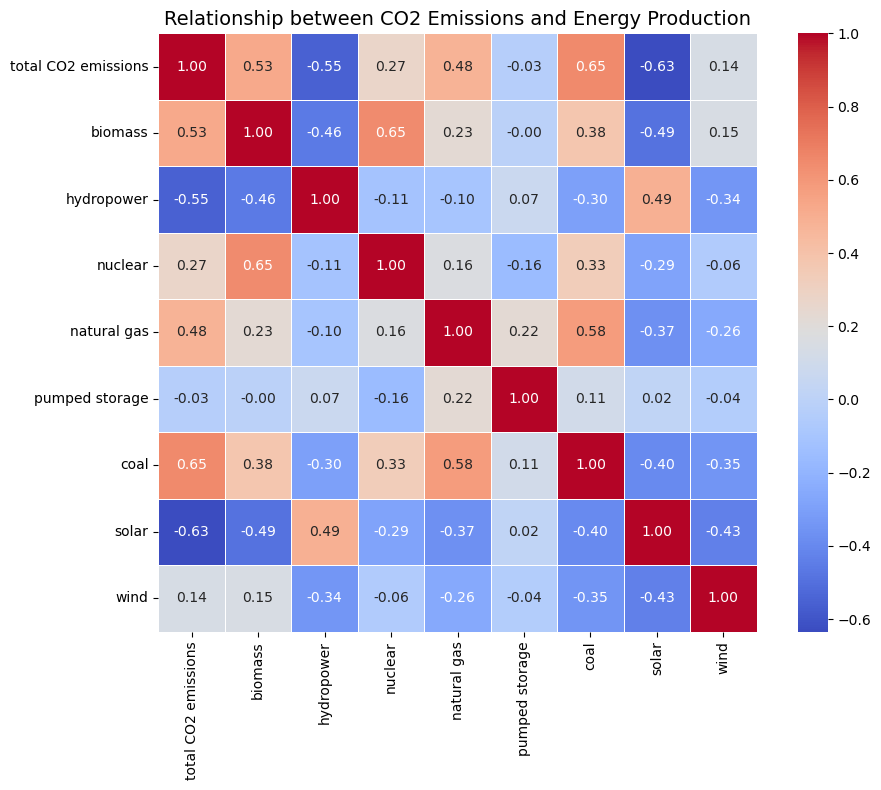

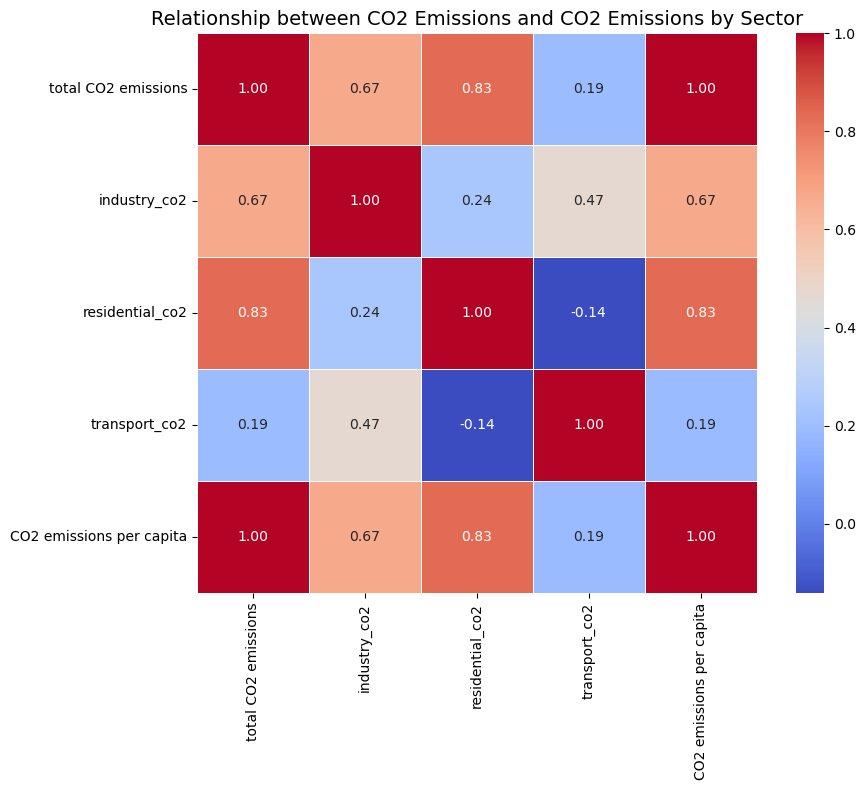

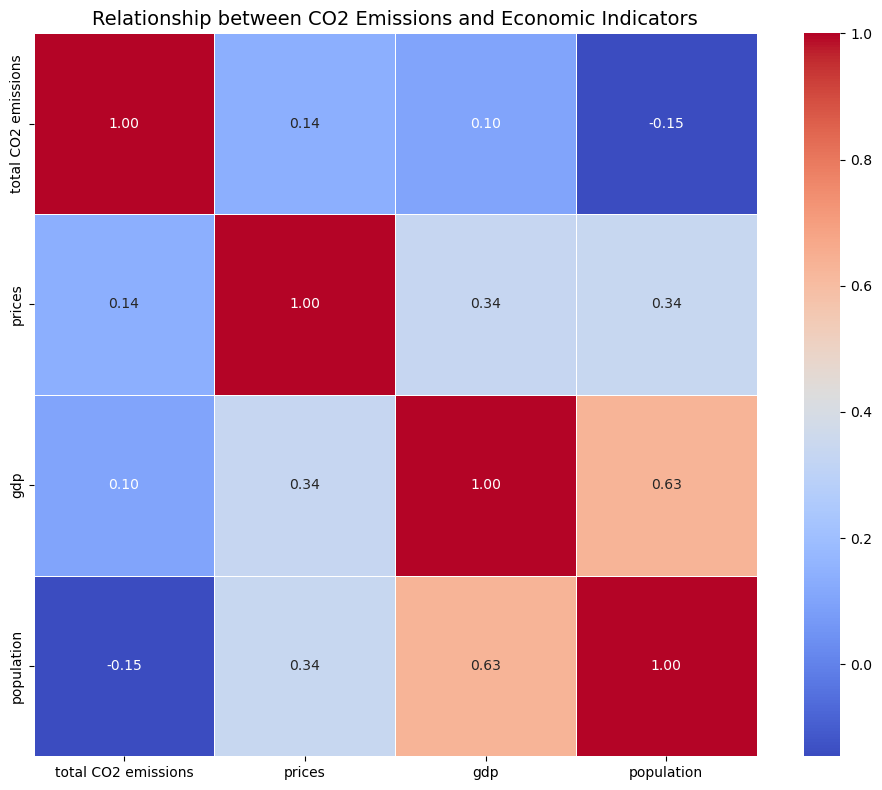

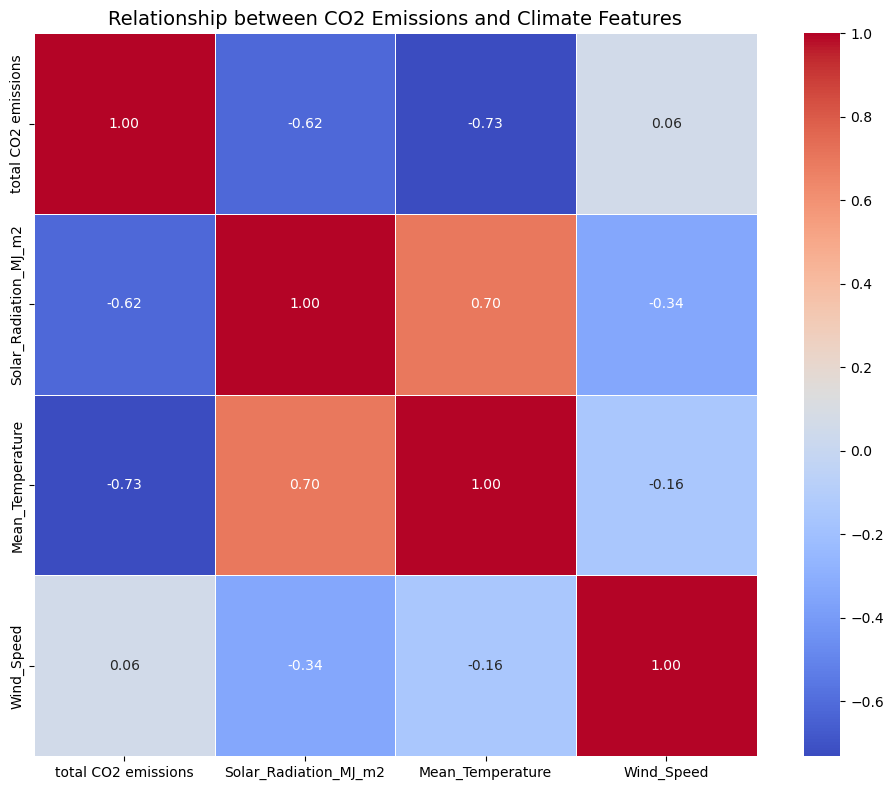

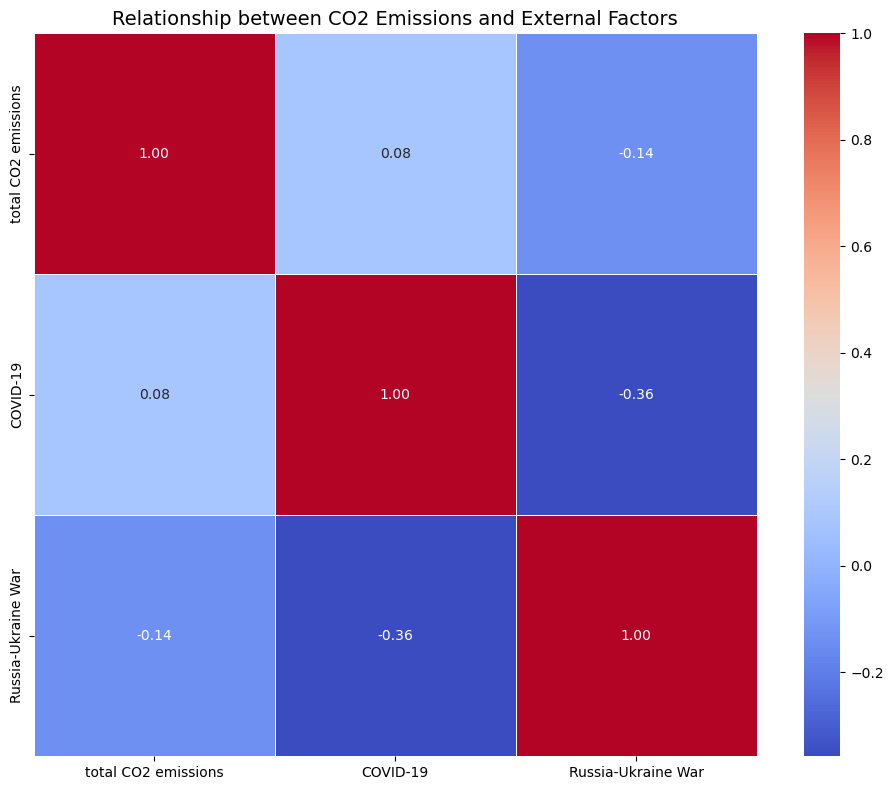

In [32]:
# Perform and plot correlation for each group
for group_name, variables in groups.items():
    # Ensure target variables are included in each group
    group_data = analysis_data[target_variables + variables]
    
    correlation_matrix = group_data.corr()
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f",
        cbar=True, square=True, linewidths=0.5
    )
    plt.title(f"Relationship between CO2 Emissions and {group_name}", fontsize=14)
    plt.tight_layout()
    
    # Dynamically generate a filename based on the group name
    filename = f"plots/Correlation_co2_{group_name.replace(' ', '_')}.png"
    
    plt.savefig(filename, bbox_inches='tight')
    plt.show()

#### Multicollinearity Check ####

In [233]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [234]:
# Define Target Variable
target_co2 = "total CO2 emissions"

In [235]:
# Define independent variables for CO₂ Model (excluding the target variable)
auxiliary_co2 =  ['biomass', 'hydropower', 'nuclear', 'natural gas', 'coal', 
                'solar', 'wind', 'industry_co2', 'residential_co2', 'transport_co2', 
                'total energy consumption', 'gdp', 'population', 'GDP per capita', 
                'PEC per capita', 'Solar_Radiation_MJ_m2', 'Mean_Temperature', 'Wind_Speed', 
                'COVID-19', 'Russia-Ukraine War', 'primary energy consumption']

In [236]:
# Function to calculate VIF iteratively
def calculate_vif_iteratively(data, features, threshold=10):
    X = df[features]  # Select relevant columns
    while True:
        vif_data = pd.DataFrame()
        vif_data["Feature"] = X.columns
        vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
        
        max_vif = vif_data["VIF"].max()  # Get the highest VIF value
        if max_vif < threshold:  # Stop if all VIF values are below threshold
            break
        
        # Drop feature with the highest VIF
        feature_to_remove = vif_data.sort_values("VIF", ascending=False)["Feature"].iloc[0]
        print(f"Removing {feature_to_remove} with VIF = {max_vif:.2f}")
        
        features.remove(feature_to_remove)  # Remove from list
        X = df[features]  # Update dataset
    
    return vif_data  # Return final selected features

In [237]:
# Run iterative VIF reduction for CO₂ Model
print("\nFinal VIF Results for CO₂ Emissions Model:")
vif_co2 = calculate_vif_iteratively(data, co2_features)
print(vif_co2)


Final VIF Results for CO₂ Emissions Model:
Removing total CO2 emissions with VIF = 41910.84
Removing industry_co2 with VIF = 64.35
Removing transport_co2 with VIF = 28.96
Removing electricity_co2 with VIF = 12.45
           Feature       VIF
0     aviation_co2  2.361565
1  residential_co2  2.361565
